### Compréhension du problème

Dans ce devoir on veut prédire la consommation de carburant mpg (miles par gallon) d'une voiture à partir de ses caractéristiques (poids, puissance, cylindrée, etc.).

On traite le problème de deux façons :
- **Classification (SVC)** : on transforme mpg en 3 classes (faible, moyenne, élevée) et on prédit la classe.
- **Régression (SVR)** : on garde mpg comme valeur réelle et on prédit directement sa valeur.

Pour chaque partie on fait : le prétraitement, une implémentation **from scratch** (codée par nous), puis une comparaison avec scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC, SVR
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)



data = sns.load_dataset('mpg')

data.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


### Collecte et compréhension des données

Cette étape sert à connaître la taille du dataset, le type de chaque colonne, les valeurs manquantes et les doublons.

In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [3]:
print("Valeurs manquantes par colonne :")
print(data.isnull().sum())
print("\nNombre de doublons :", data.duplicated().sum())

Valeurs manquantes par colonne :
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Nombre de doublons : 0


In [4]:
data.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


Le dataset contient 398 lignes et 9 colonnes. Seule la variable horsepower a des valeurs manquantes (6 lignes) et il n’y a aucun doublon. On enlève la colonne name, qui est juste un identifiant. Les variables continues sont displacement, horsepower, weight, acceleration et model_year ; cylinders et origin sont catégorielles. Les échelles sont très différentes (weight va de 1613 à 5140, acceleration de 8 à 25), donc il faudra normaliser avant d’utiliser un SVM.

### Analyse de la cible et des corrélations

On regarde la distribution de mpg, son lien avec origin et cylinders, puis la matrice de corrélation pour voir quelles variables sont liées à mpg et si les variables sont liées entre elles. Ça nous aide à comprendre les données avant de choisir le prétraitement.

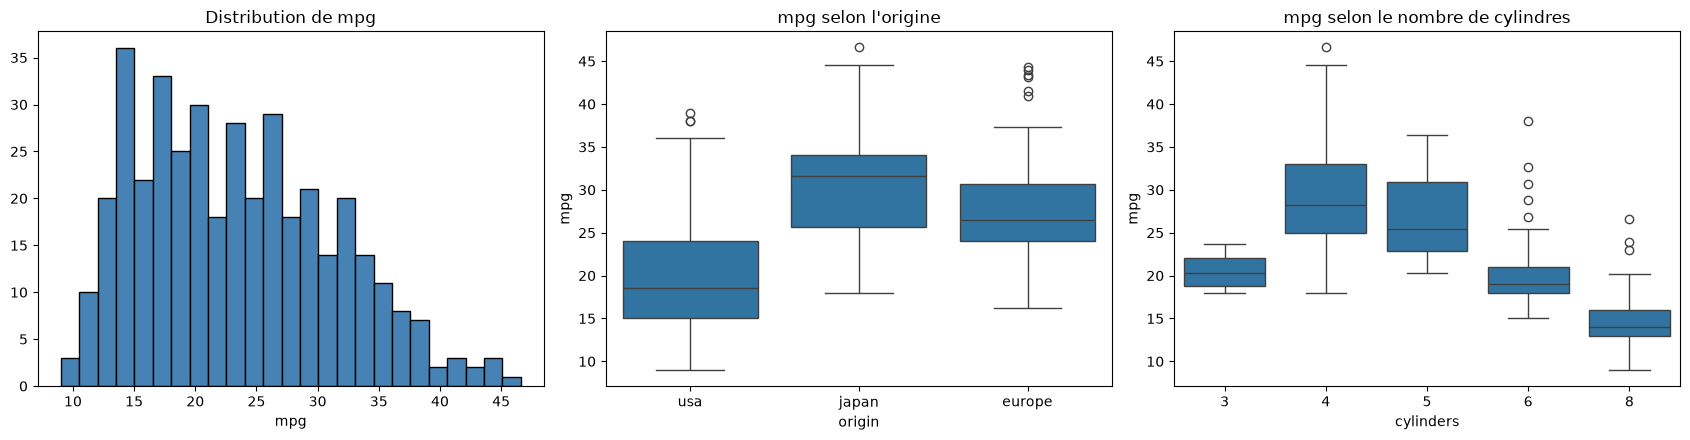

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].hist(data['mpg'], bins=25, color='steelblue', edgecolor='k')
axes[0].set_title("Distribution de mpg"); axes[0].set_xlabel("mpg")
#selon l'origine:
sns.boxplot(data=data, x='origin', y='mpg', ax=axes[1])
axes[1].set_title("mpg selon l'origine")

#selon le nombre de cylindres:
sns.boxplot(data=data, x='cylinders', y='mpg', ax=axes[2])
axes[2].set_title("mpg selon le nombre de cylindres")
plt.tight_layout(); 
plt.show()

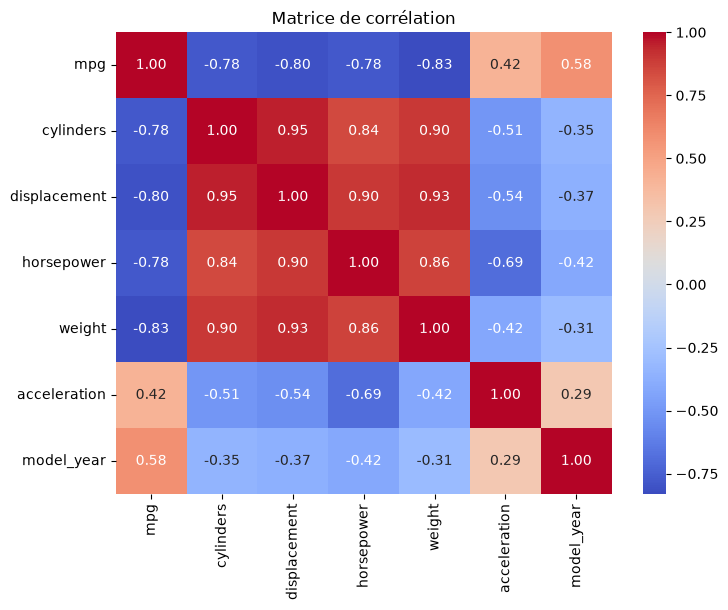

In [6]:
plt.figure(figsize=(8, 6))
corr = data.drop(columns=['name']).corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Matrice de corrélation")
plt.show()

Resultats :
- mpg va de 9 à 46.6 avec une moyenne de 23.4, et la distribution est un peu étalée vers la droite
- les voitures américaines consomment plus (environ 20 mpg en moyenne) que les voitures japonaises (environ 30 mpg)
- plus il y a de cylindres, plus la voiture consomme (8 cylindres : environ 15 mpg, 4 cylindres : environ 29 mpg)

Variables les plus corrélées avec mpg :
- weight : -0.83
- displacement : -0.81
- cylinders : -0.78
- horsepower : -0.78
- model_year : +0.58

Donc plus la voiture est lourde et puissante, plus elle consomme. Les voitures plus récentes consomment moins.

Relations entre les variables : displacement, cylinders, weight et horsepower sont très corrélées entre elles (entre 0.84 et 0.95), il y a donc de la multicolinéarité. Ce n'est pas un gros problème pour un SVM, mais ça explique pourquoi un modèle linéaire marche déjà assez bien.

### Prétraitement des données

Ce qu'on fait  :
- **Valeurs manquantes** : on supprime les 6 lignes sans horsepower (seulement 1.5 % des données)
- **Colonne name** : on la supprime, c'est juste un identifiant
- **Valeurs aberrantes (outliers)** : on vérifie avec la méthode de l'IQR sur mpg
- **Normalisation** (StandardScaler) des variables continues : le SVM utilise des distances, donc une variable avec de grandes valeurs comme weight dominerait les autres
- **Encodage One-Hot** de cylinders et origin : ce sont des catégories, on évite de donner un ordre entre elles
- Le scaler est ajusté **seulement sur le train**, pour ne pas utiliser des informations du test

In [7]:
# Suppression des valeurs manquantes et de la colonne name
df = data.dropna().drop(columns=['name'])
print("Taille après nettoyage :", df.shape)

# Détection des outliers sur mpg (méthode IQR)
Q1, Q3 = df['mpg'].quantile(0.25), df['mpg'].quantile(0.75)
IQR = Q3 - Q1
borne_inf, borne_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
nb_outliers = ((df['mpg'] < borne_inf) | (df['mpg'] > borne_sup)).sum()
print(f"Bornes IQR : [{borne_inf:.1f}, {borne_sup:.1f}]  ->  {nb_outliers} outlier(s)")

Taille après nettoyage : (392, 8)
Bornes IQR : [-1.0, 47.0]  ->  0 outlier(s)


La méthode de l'IQR : on calcule Q1 (25 % des données sont en dessous) et Q3 (75 % sont en dessous), puis IQR = Q3 - Q1. Une valeur est aberrante si elle est en dehors de [Q1 - 1.5 IQR, Q3 + 1.5 IQR].

On remarque qu'il n'y a **aucun outlier** (le maximum 46.6 est plus petit que la borne 47), donc on ne supprime aucune ligne. On garde toutes les données car on a seulement 392 exemples.

In [8]:
# Variables continues et catégorielles
num_cols = ['displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
cat_cols = ['cylinders', 'origin']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(sparse_output=False), cat_cols)
])

X = df.drop(columns=['mpg'])

## Problème de classification (SVC)

### Discrétisation de la cible:

On transforme mpg en 3 classes : faible, moyenne et élevée. On compare deux stratégies :
1. **Quantiles** (pd.qcut) : chaque classe a à peu près le même nombre d'exemples
2. **Seuils fixes** (pd.cut) : on choisit nous-mêmes les seuils (20 et 30 mpg)

 une classe « élevée » veut dire beaucoup de miles par gallon, donc une voiture qui consomme peu.

Seuils des quantiles : [18.733 26.933]
Effectifs qcut : [131, 130, 131]
Effectifs fixes : [160, 149, 83]
Accuracy RBF avec qcut : 0.8481
Accuracy RBF avec seuils fixes : 0.8228


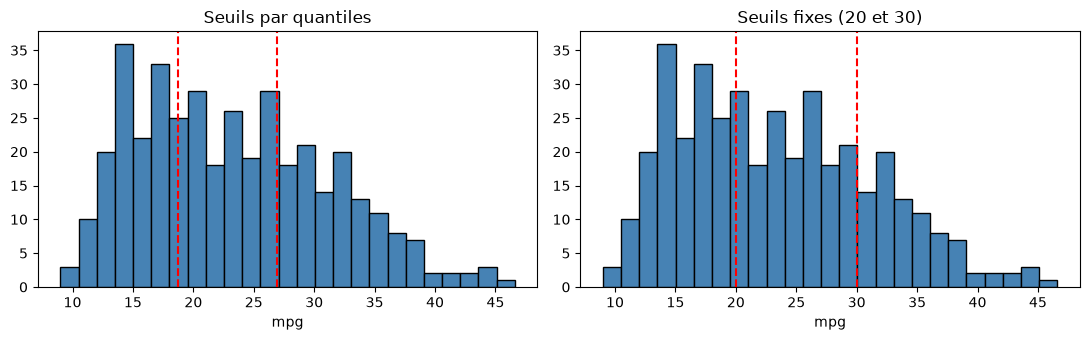

In [9]:
labels = ['faible', 'moyenne', 'elevee']

y_qcut = pd.qcut(df['mpg'], q=3, labels=labels)
y_fixe = pd.cut(df['mpg'], bins=[0, 20, 30, 100], labels=labels)

seuils_q = pd.qcut(df['mpg'], q=3).cat.categories.right.values[:2]
print("Seuils des quantiles :", seuils_q)
print("Effectifs qcut :", y_qcut.value_counts()[labels].tolist())
print("Effectifs fixes :", y_fixe.value_counts()[labels].tolist())


def acc_rbf(y):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    Xtr_s = preprocessor.fit_transform(Xtr)
    Xte_s = preprocessor.transform(Xte)
    return accuracy_score(yte, SVC(kernel='rbf').fit(Xtr_s, ytr).predict(Xte_s))

print("Accuracy RBF avec qcut :", round(acc_rbf(y_qcut), 4))
print("Accuracy RBF avec seuils fixes :", round(acc_rbf(y_fixe), 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, seuils, titre in zip(axes, [seuils_q, [20, 30]], ["Seuils par quantiles", "Seuils fixes (20 et 30)"]):
    ax.hist(df['mpg'], bins=25, color='steelblue', edgecolor='k')
    for s in seuils:
        ax.axvline(s, color='r', ls='--')
    ax.set_title(titre); ax.set_xlabel("mpg")
plt.tight_layout(); plt.show()

On remarque que :
- avec les quantiles, les 3 classes sont équilibrées (131 / 130 / 131)
- avec les seuils fixes, la classe « élevée » est beaucoup plus petite (83 exemples contre 160 pour « faible »), car il y a peu de voitures avec un mpg élevé
- l'accuracy du SVC RBF est de 0.848 avec les quantiles et 0.823 avec les seuils fixes (à comparer avec prudence car les classes ne sont pas les mêmes)

Impact sur le problème :
- quand les classes sont déséquilibrées, le modèle favorise les grosses classes et l'accuracy devient moins fiable
- mpg est continue, donc deux voitures proches d'un seuil sont presque pareilles mais dans des classes différentes : le problème devient plus difficile autour des seuils (surtout pour la classe « moyenne » qui est entre les deux autres)

On choisit donc les **quantiles** pour la suite.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_qcut, test_size=0.2, stratify=y_qcut, random_state=42
)

# Prétraitement 
X_train_s = preprocessor.fit_transform(X_train)
X_test_s = preprocessor.transform(X_test)
print("Train :", X_train_s.shape, " Test :", X_test_s.shape)

Train : (313, 13)  Test : (79, 13)


### SVC from scratch avec l'algorithme SMO


Le SVC cherche l'hyperplan qui sépare les classes avec la marge maximale. On résout le problème dual en cherchant les coefficients $\alpha_i$ ($0 \le \alpha_i \le C$) qui maximisent :
$$\sum_{i=1}^n \alpha_i - \frac{1}{2} \sum_{i=1}^n \sum_{j=1}^n \alpha_i \alpha_j y_i y_j K(x_i, x_j)$$
sous la contrainte $\sum_{i=1}^n \alpha_i y_i = 0$.

L'algorithme SMO (Sequential Minimal Optimization) optimise deux coefficients $\alpha$ à la fois, ce qui offre une mise à jour analytique simple à chaque étape. Les exemples pour lesquels $\alpha_i > 0$ constituent les vecteurs de support. Pour traiter le problème à 3 classes, nous utilisons la stratégie « un-contre-tous » (One-vs-Rest) en entraînant un classifieur par classe et en retenant celle qui produit le score le plus élevé.

In [11]:
class SVC_SMO:
    # SVM binaire (labels -1 / +1) entraîné avec l'algorithme SMO
    def __init__(self, C=1.0, kernel='rbf', gamma=0.1, tol=1e-3, max_passes=5, max_iter=300):
        self.C = C
        self.kernel = kernel
        self.gamma = gamma
        self.tol = tol                  # tolérance sur les conditions KKT
        self.max_passes = max_passes    # nb de passages sans changement avant d'arrêter
        self.max_iter = max_iter

    def noyau(self, A, B):
        if self.kernel == 'linear':
            return A @ B.T
        # RBF : ||a-b||^2 = ||a||^2 + ||b||^2 - 2 a.b
        d = np.sum(A**2, axis=1).reshape(-1, 1) + np.sum(B**2, axis=1) - 2 * A @ B.T
        return np.exp(-self.gamma * np.maximum(d, 0))

    def fit(self, X, y):
        n = len(y)
        K = self.noyau(X, X)            # matrice de Gram
        C, tol = self.C, self.tol
        alpha = np.zeros(n)
        b = 0.0
        passes, it = 0, 0

        while passes < self.max_passes and it < self.max_iter:
            n_changed = 0
            for i in range(n):
                E = (alpha * y) @ K + b - y          # erreurs f(x) - y de tous les points
                Ei = E[i]
                # le point i viole-t-il les conditions KKT ?
                if (y[i] * Ei < -tol and alpha[i] < C) or (y[i] * Ei > tol and alpha[i] > 0):
                    # candidats j classés par |Ei - Ej| décroissant
                    for j in np.argsort(-np.abs(Ei - E)):
                        if j == i:
                            continue
                        ai, aj = alpha[i], alpha[j]

                        # bornes L et H pour alpha_j
                        if y[i] != y[j]:
                            L, H = max(0, aj - ai), min(C, C + aj - ai)
                        else:
                            L, H = max(0, ai + aj - C), min(C, ai + aj)
                        if L == H:
                            continue

                        eta = 2 * K[i, j] - K[i, i] - K[j, j]
                        if eta >= 0:
                            continue

                        # nouvelle valeur de alpha_j (coupée dans [L, H]) puis alpha_i
                        aj_new = np.clip(aj - y[j] * (Ei - E[j]) / eta, L, H)
                        if abs(aj_new - aj) < 1e-5:
                            continue
                        alpha[j] = aj_new
                        alpha[i] = ai + y[i] * y[j] * (aj - aj_new)

                        # mise à jour du biais b
                        b1 = b - Ei - y[i] * (alpha[i] - ai) * K[i, i] - y[j] * (alpha[j] - aj) * K[i, j]
                        b2 = b - E[j] - y[i] * (alpha[i] - ai) * K[i, j] - y[j] * (alpha[j] - aj) * K[j, j]
                        if 0 < alpha[i] < C:
                            b = b1
                        elif 0 < alpha[j] < C:
                            b = b2
                        else:
                            b = (b1 + b2) / 2
                        n_changed += 1
                        break
            passes = passes + 1 if n_changed == 0 else 0
            it += 1

        self.alpha, self.b, self.X, self.y = alpha, b, X, y
        self.n_sv = int((alpha > 1e-5).sum())   # nombre de vecteurs de support
        return self

    def decision(self, X):
        return self.noyau(X, self.X) @ (self.alpha * self.y) + self.b


class SVC_multiclasse:
    # Un-contre-tous : un SVM binaire par classe
    def __init__(self, **params):
        self.params = params

    def fit(self, X, y):
        self.classes = np.unique(y)
        self.modeles = []
        for c in self.classes:
            y_bin = np.where(y == c, 1, -1)       # classe c contre les autres
            self.modeles.append(SVC_SMO(**self.params).fit(X, y_bin))
        return self

    def predict(self, X):
        scores = np.column_stack([m.decision(X) for m in self.modeles])
        return self.classes[np.argmax(scores, axis=1)]

### Entraînement et comparaison avec scikit-learn

Pour comparer correctement, on utilise les **mêmes paramètres** : C = 1 et gamma = 1 / (nombre de variables × variance de X), qui est le gamma='scale' de sklearn. On teste le noyau linéaire et le noyau RBF.

In [12]:
gamma = 1 / (X_train_s.shape[1] * X_train_s.var())
print("gamma =", round(gamma, 4))

modeles_scratch, modeles_sk = {}, {}
resultats = {}
for kernel in ['linear', 'rbf']:
    modeles_scratch[kernel] = SVC_multiclasse(C=1.0, kernel=kernel, gamma=gamma).fit(X_train_s, y_train.values)
    acc_scratch = accuracy_score(y_test, modeles_scratch[kernel].predict(X_test_s))

    modeles_sk[kernel] = SVC(C=1.0, kernel=kernel, gamma='scale').fit(X_train_s, y_train)
    acc_sk = accuracy_score(y_test, modeles_sk[kernel].predict(X_test_s))

    resultats[kernel] = [acc_scratch, acc_sk]

tableau = pd.DataFrame(resultats, index=['From scratch (SMO)', 'Scikit-learn']).T
tableau.round(4)

gamma = 0.1494


,From scratch (SMO),Scikit-learn
linear,0.8101,0.8228
rbf,0.8481,0.8481


From scratch (RBF): 
              precision    recall  f1-score   support

      faible      0.839     1.000     0.912        26
     moyenne      0.792     0.731     0.760        26
      elevee      0.917     0.815     0.863        27

    accuracy                          0.848        79
   macro avg      0.849     0.849     0.845        79
weighted avg      0.850     0.848     0.845        79

Scikit-learn (RBF): 
              precision    recall  f1-score   support

      faible      0.839     1.000     0.912        26
     moyenne      0.792     0.731     0.760        26
      elevee      0.917     0.815     0.863        27

    accuracy                          0.848        79
   macro avg      0.849     0.849     0.845        79
weighted avg      0.850     0.848     0.845        79



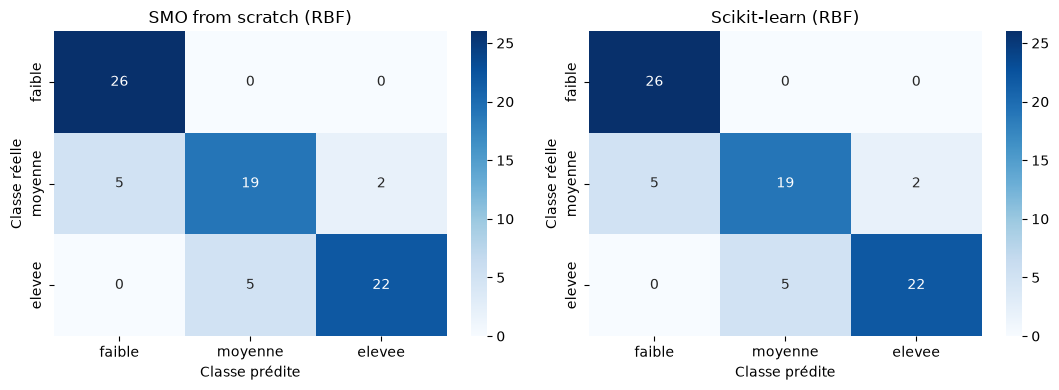

In [13]:
# Rapport de classification et matrices de confusion (noyau RBF)
pred_scratch = modeles_scratch['rbf'].predict(X_test_s)
pred_sk = modeles_sk['rbf'].predict(X_test_s)

print("From scratch (RBF): ")
print(classification_report(y_test, pred_scratch, labels=labels, digits=3))
print("Scikit-learn (RBF): ")
print(classification_report(y_test, pred_sk, labels=labels, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, titre in zip(axes, [pred_scratch, pred_sk], ["SMO from scratch (RBF)", "Scikit-learn (RBF)"]):
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(titre); ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")
plt.tight_layout(); plt.show()

### Interprétation des résultats du SVC

**Accuracy**
- avec le noyau RBF, notre SMO et scikit-learn donnent exactement la même accuracy : 0.848 (67 voitures bien classées sur 79), et le même rapport de classification. Donc les deux trouvent la même solution
- avec le noyau linéaire, la différence est d'un seul exemple sur 79 (0.810 contre 0.823), à cause de la tolérance d'arrêt de SMO

**Linéaire contre RBF**
- le RBF est un peu meilleur (2 à 3 exemples de plus sur 79), donc la séparation n'est pas complètement linéaire
- mais l'écart est petit, et avec un seul découpage train/test on ne peut pas conclure fortement

**Par classe (rapport de classification)**
- classe « faible » : rappel = 1.0, toutes les voitures « faible » sont trouvées, mais la précision est 0.84 car 5 voitures « moyenne » sont prédites « faible »
- classe « moyenne » : c'est la plus difficile (F1 = 0.76) parce qu'elle est entre les deux autres classes
- classe « élevée » : elle a la meilleure précision (0.92)

**Matrice de confusion**
- les erreurs sont presque toutes entre classes voisines (faible/moyenne et moyenne/élevée), et jamais entre « faible » et « élevée »
- c'est normal car on a coupé une valeur continue en classes : les voitures proches d'un seuil se ressemblent

##  Problème de régression (SVR)

###  Modèle et implémentation from scratch
Pour la régression SVR, la fonction de perte $\epsilon$-insensible est définie par :
$$L_\epsilon(y, f(x)) = \max(0, |y - f(x)| - \epsilon)$$
Cette fonction n'impose aucune pénalité aux erreurs inférieures à $\epsilon$. On cherche à minimiser la fonction d'objectif :
$$\frac{1}{2} \|w\|^2 + C \sum_{i=1}^n L_\epsilon(y_i, f(x_i))$$
par descente de sous-gradient. Les points situés à l'intérieur du tube $\epsilon$ n'ont aucun impact sur la solution, tandis que ceux situés sur la frontière ou à l'extérieur deviennent les vecteurs de support. Remarque : le paramètre $\epsilon$ est exprimé directement dans l'unité de la cible (miles par gallon, mpg) car celle-ci n'est pas normalisée.


In [14]:
class SVR_lineaire:
    # SVR linéaire avec perte epsilon-insensible (descente de sous-gradient)
    def __init__(self, epsilon=1.0, C=1.0, n_iter=5000, lr0=1e-3):
        self.epsilon = epsilon
        self.C = C
        self.n_iter = n_iter
        self.lr0 = lr0

    def fit(self, X, y):
        w = np.zeros(X.shape[1])
        b = y.mean()
        for t in range(self.n_iter):
            r = y - (X @ w + b)                              # résidus
            s = np.sign(r) * (np.abs(r) > self.epsilon)      # 0 si le point est dans le tube
            grad_w = w - self.C * (X.T @ s)
            grad_b = -self.C * s.sum()
            lr = self.lr0 / np.sqrt(1 + t / 50)              # pas décroissant
            w = w - lr * grad_w
            b = b - lr * grad_b
        self.w, self.b = w, b
        # vecteurs de support = points sur le bord ou en dehors du tube
        self.n_sv = int(np.sum(np.abs(y - (X @ w + b)) >= self.epsilon - 1e-2))
        return self

    def predict(self, X):
        return X @ self.w + self.b

def rmse(y_vrai, y_pred):
    return np.sqrt(mean_squared_error(y_vrai, y_pred))

In [15]:
# Données pour la régression (cible continue)
y_reg = df['mpg']
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(X, y_reg, test_size=0.2, random_state=42)
A = preprocessor.fit_transform(Xtr_r)
B = preprocessor.transform(Xte_r)

# Modèle de référence : epsilon = 1
svr_scratch = SVR_lineaire(epsilon=1.0, C=1.0).fit(A, ytr_r.values)
svr_sk = SVR(kernel='linear', epsilon=1.0, C=1.0).fit(A, ytr_r)

p_scratch = svr_scratch.predict(B)
p_sk = svr_sk.predict(B)

resume = pd.DataFrame({
    'MSE':  [mean_squared_error(yte_r, p_scratch), mean_squared_error(yte_r, p_sk)],
    'RMSE': [rmse(yte_r, p_scratch), rmse(yte_r, p_sk)],
    'MAE':  [mean_absolute_error(yte_r, p_scratch), mean_absolute_error(yte_r, p_sk)],
    'R2':   [r2_score(yte_r, p_scratch), r2_score(yte_r, p_sk)],
    'Vecteurs de support': [svr_scratch.n_sv, len(svr_sk.support_)]
}, index=['From scratch', 'Scikit-learn'])
resume.round(3)

,MSE,RMSE,MAE,R2,Vecteurs de support
From scratch,8.404,2.899,2.140,0.835,216
Scikit-learn,8.239,2.870,2.124,0.839,215


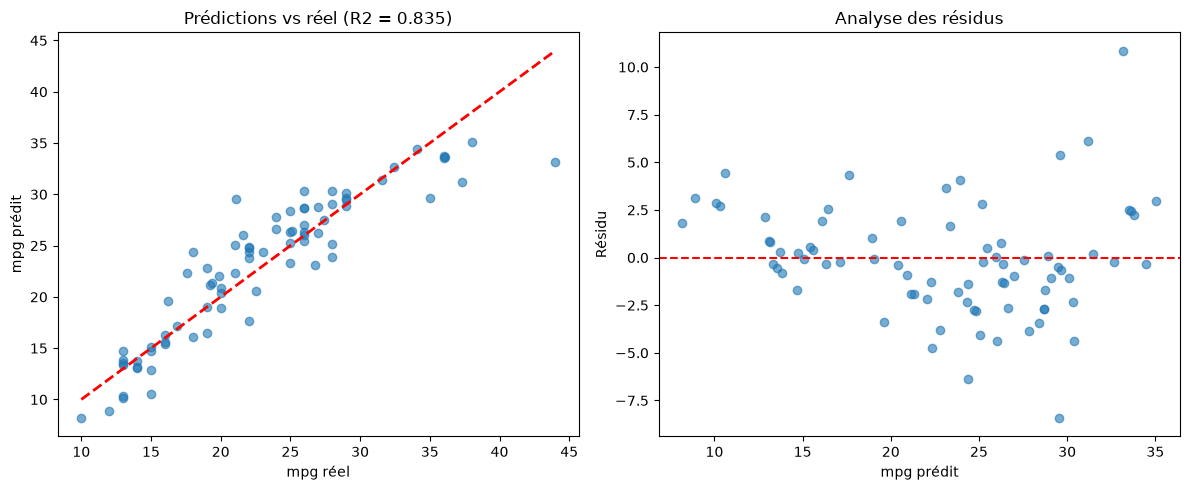

In [16]:
# Prédictions vs valeurs réelles et résidus (modèle from scratch)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(yte_r, p_scratch, alpha=0.6)
plt.plot([yte_r.min(), yte_r.max()], [yte_r.min(), yte_r.max()], 'r--', lw=2)
plt.xlabel('mpg réel'); plt.ylabel('mpg prédit')
plt.title(f"Prédictions vs réel (R2 = {r2_score(yte_r, p_scratch):.3f})")

plt.subplot(1, 2, 2)
plt.scatter(p_scratch, yte_r - p_scratch, alpha=0.6)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('mpg prédit'); plt.ylabel('Résidu')
plt.title("Analyse des résidus")

plt.tight_layout(); plt.show()

### Interprétation des résultats du SVR (ε = 1)

**Comparaison**
- notre SVR et celui de scikit-learn sont très proches : MSE 8.4 contre 8.2, RMSE 2.90 contre 2.87, MAE 2.14 contre 2.12, R² 0.835 contre 0.839, et presque le même nombre de vecteurs de support (216 contre 215)
- donc notre descente de sous-gradient converge bien vers la bonne solution

**Les métriques**
- MSE : moyenne des erreurs au carré. Le RMSE est sa racine carrée (en unité de mpg). Elles pénalisent plus les grosses erreurs
- MAE = 2.14 : en moyenne on se trompe d'environ 2.1 mpg, sur une consommation moyenne de 23.4 mpg (environ 9 %)
- R² = 0.835 : le modèle explique environ 83 % de la variation de mpg, c'est bien pour un modèle linéaire

**Les graphiques**
- les points sont proches de la diagonale, donc les prédictions suivent bien les vraies valeurs
- les mpg très élevés (plus de 35) sont sous-estimés (par exemple une voiture à 44 mpg est prédite autour de 33)
- les résidus sont positifs aux extrémités et plutôt négatifs au milieu, donc il y a une petite non-linéarité que la droite ne capture pas. Ils sont aussi plus dispersés pour les grandes valeurs prédites

### Influence de ε sur le nombre de vecteurs de support

On entraîne le SVR avec plusieurs valeurs de $\varepsilon$ et on compare le nombre de vecteurs de support et l'erreur sur le test (scratch et sklearn).

 epsilon  SV scratch  SV sklearn  RMSE scratch  RMSE sklearn
     0.1         297         296         2.902         2.856
     0.5         255         255         2.929         2.890
     1.0         216         215         2.899         2.870
     2.0         144         147         2.909         2.902
     3.0          91          91         2.979         2.933
     5.0          38          40         3.127         3.151


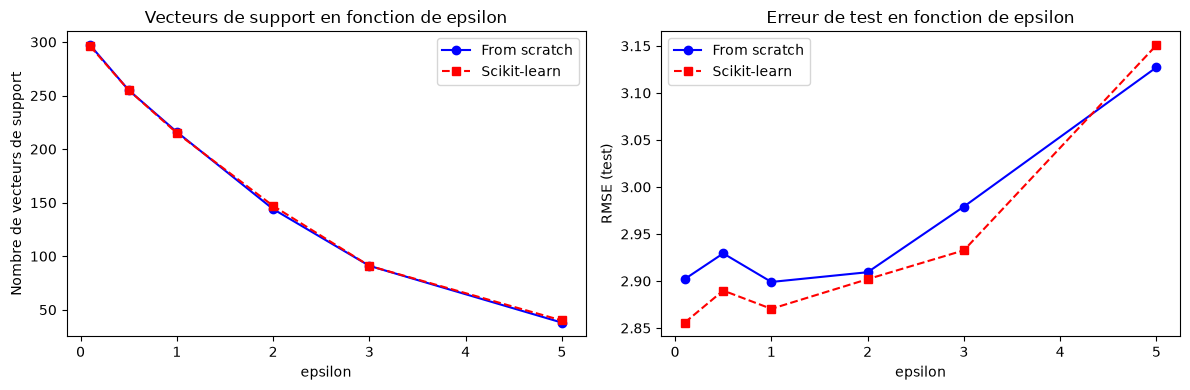

In [17]:
epsilons = [0.1, 0.5, 1.0, 2.0, 3.0, 5.0]
sv_scratch, sv_sk, rmse_scratch, rmse_sk = [], [], [], []

for eps in epsilons:
    m1 = SVR_lineaire(epsilon=eps).fit(A, ytr_r.values)
    sv_scratch.append(m1.n_sv)
    rmse_scratch.append(rmse(yte_r, m1.predict(B)))

    m2 = SVR(kernel='linear', epsilon=eps, C=1.0).fit(A, ytr_r)
    sv_sk.append(len(m2.support_))
    rmse_sk.append(rmse(yte_r, m2.predict(B)))

print(pd.DataFrame({'epsilon': epsilons,
                    'SV scratch': sv_scratch, 'SV sklearn': sv_sk,
                    'RMSE scratch': np.round(rmse_scratch, 3),
                    'RMSE sklearn': np.round(rmse_sk, 3)}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epsilons, sv_scratch, 'b-o', label='From scratch')
axes[0].plot(epsilons, sv_sk, 'r--s', label='Scikit-learn')
axes[0].set_xlabel('epsilon'); axes[0].set_ylabel('Nombre de vecteurs de support')
axes[0].set_title("Vecteurs de support en fonction de epsilon"); axes[0].legend()

axes[1].plot(epsilons, rmse_scratch, 'b-o', label='From scratch')
axes[1].plot(epsilons, rmse_sk, 'r--s', label='Scikit-learn')
axes[1].set_xlabel('epsilon'); axes[1].set_ylabel('RMSE (test)')
axes[1].set_title("Erreur de test en fonction de epsilon"); axes[1].legend()
plt.tight_layout(); plt.show()

Resultats:
- notre SVR et celui de scikit-learn donnent presque les mêmes résultats
- quand $\varepsilon$ augmente, le tube devient plus large, plus de points sont dedans, donc le **nombre de vecteurs de support diminue beaucoup** (d'environ 300 à une quarantaine)
- l'erreur de test reste stable pour les petits $\varepsilon$, puis elle augmente quand $\varepsilon$ est trop grand : le tube est trop large et le modèle ignore des écarts qui sont utiles (sous-apprentissage)

### Visualisation du tube ε

Pour bien voir le tube, on refait le SVR avec une seule variable (weight, normalisé). Les points entourés en rouge sont les vecteurs de support.

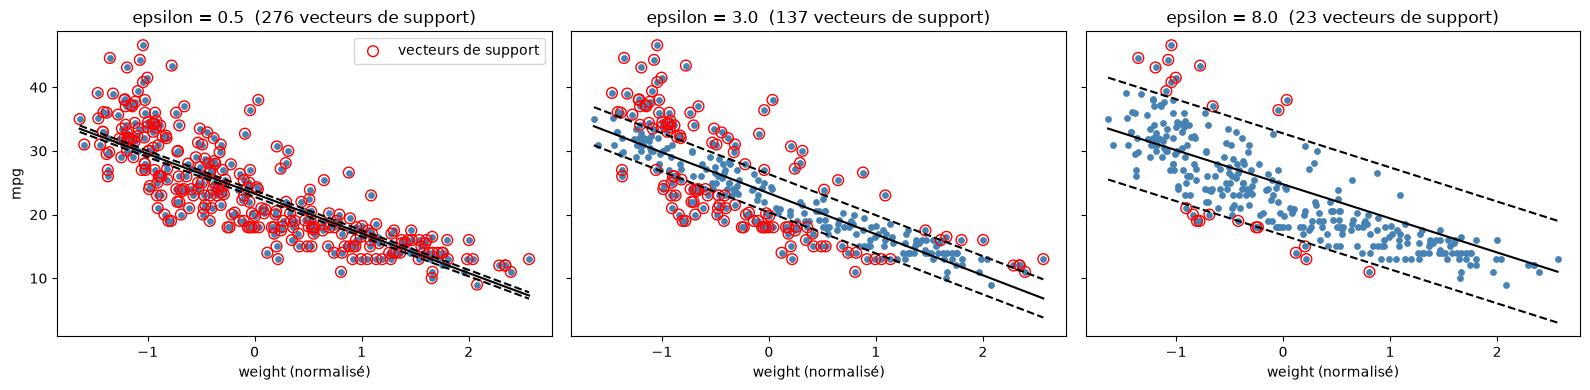

In [18]:
# Une seule variable : weight (3e colonne des variables continues)
xw = A[:, [2]]
yw = ytr_r.values
ordre = np.argsort(xw[:, 0])

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, eps in zip(axes, [0.5, 3.0, 8.0]):
    m = SVR_lineaire(epsilon=eps).fit(xw, yw)
    f = m.predict(xw)
    sv = np.abs(yw - f) >= eps - 1e-2
    ax.scatter(xw[:, 0], yw, s=15, c='steelblue')
    ax.scatter(xw[sv, 0], yw[sv], s=60, facecolors='none', edgecolors='r', label='vecteurs de support')
    ax.plot(xw[ordre, 0], f[ordre], 'k-')
    ax.plot(xw[ordre, 0], f[ordre] + eps, 'k--')
    ax.plot(xw[ordre, 0], f[ordre] - eps, 'k--')
    ax.set_title(f"epsilon = {eps}  ({sv.sum()} vecteurs de support)")
    ax.set_xlabel('weight (normalisé)')
axes[0].set_ylabel('mpg'); axes[0].legend()
plt.tight_layout(); plt.show()

Resultats:
- avec un petit $\varepsilon$, presque tous les points sont en dehors du tube, donc presque tous sont des vecteurs de support
- avec un grand $\varepsilon$, la plupart des points sont dans le tube et il reste seulement quelques points extrêmes comme vecteurs de support
- la droite garde à peu près la même pente : seuls les points hors du tube influencent la solution

###  Capacité à ignorer le bruit
Pour tester ça, on ajoute un bruit gaussien (écart-type = 3 mpg) sur les mpg d'entraînement seulement, puis on mesure l'erreur sur le test sans bruit. On répète 10 fois avec des bruits différents et on prend la moyenne.

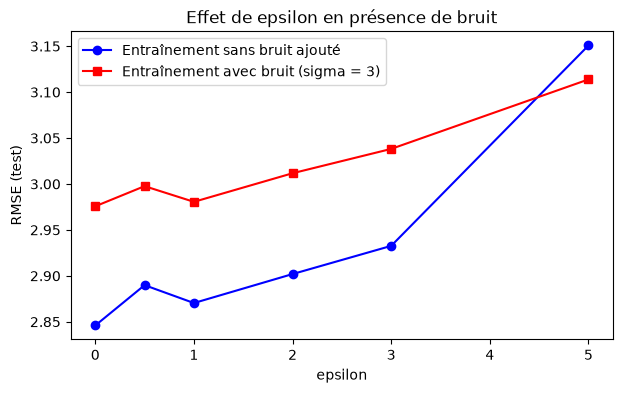

 epsilon  RMSE sans bruit  RMSE avec bruit
     0.0            2.846            2.976
     0.5            2.890            2.998
     1.0            2.870            2.981
     2.0            2.902            3.012
     3.0            2.933            3.038
     5.0            3.151            3.114


In [19]:
rng = np.random.default_rng(0)
eps_bruit = [0.0, 0.5, 1.0, 2.0, 3.0, 5.0]
rmse_propre, rmse_bruite = [], []

for eps in eps_bruit:
    # Données d'entraînement sans bruit ajouté
    m = SVR(kernel='linear', epsilon=eps, C=1.0).fit(A, ytr_r)
    rmse_propre.append(rmse(yte_r, m.predict(B)))

    # Données d'entraînement avec bruit gaussien (10 tirages)
    erreurs = []
    for _ in range(10):
        y_bruit = ytr_r.values + rng.normal(0, 3, len(ytr_r))
        mb = SVR(kernel='linear', epsilon=eps, C=1.0).fit(A, y_bruit)
        erreurs.append(rmse(yte_r, mb.predict(B)))
    rmse_bruite.append(np.mean(erreurs))

plt.figure(figsize=(7, 4))
plt.plot(eps_bruit, rmse_propre, 'b-o', label='Entraînement sans bruit ajouté')
plt.plot(eps_bruit, rmse_bruite, 'r-s', label='Entraînement avec bruit (sigma = 3)')
plt.xlabel('epsilon'); plt.ylabel('RMSE (test)')
plt.title("Effet de epsilon en présence de bruit"); plt.legend()
plt.show()

print(pd.DataFrame({'epsilon': eps_bruit,
                    'RMSE sans bruit': np.round(rmse_propre, 3),
                    'RMSE avec bruit': np.round(rmse_bruite, 3)}).to_string(index=False))

Resultats:
- le bruit augmente l'erreur de test d'environ 0.1 mpg (RMSE) pour les petits $\varepsilon$ (de 0 à 3)
- pour $\varepsilon = 5$, l'écart entre les deux courbes disparaît : le tube est assez large par rapport au bruit (sigma = 3), donc le modèle ne suit plus les petites fluctuations
- mais avec ce grand $\varepsilon$ l'erreur de base est plus grande (environ 3.15 contre 2.85), donc on gagne en robustesse mais on perd en précision

Conclusion : $\varepsilon$ aide à ignorer le bruit seulement s'il est du même ordre que le bruit, et il faut choisir un compromis.

## Conclusion

**Classification**
- la discrétisation par quantiles donne des classes équilibrées, alors que les seuils fixes donnent une classe plus petite
- notre SVC avec SMO (un-contre-tous) donne des résultats proches de scikit-learn pour les noyaux linéaire et RBF, et le RBF est un peu meilleur
- les erreurs sont surtout entre classes voisines

**Régression**
- $\varepsilon$ contrôle la largeur du tube : plus il est grand, moins on a de vecteurs de support et plus le modèle est simple, mais s'il est trop grand l'erreur augmente
- avec du bruit, un $\varepsilon$ de l'ordre du bruit rend le modèle moins sensible à celui-ci, mais l'erreur de base augmente : il faut un compromis

**Limites**
- un seul découpage train/test, donc les résultats peuvent changer de quelques points selon le tirage
- on aurait pu utiliser la validation croisée et chercher les meilleurs C et gamma avec une recherche par grille